In [1]:
from datetime import datetime
from IPython.display import display, Markdown
from zoneinfo import ZoneInfo

current_date = datetime.now(ZoneInfo('America/Mexico_City')).strftime("%Y-%m-%d %H:%M:%S")
formatted_text = f"""
# <font color='orange'> Fourier Analysis
<font color='green'> Made by: J. Daniel Arzate | Date: 2020 - Enero 19 </font>

<font color='red'> Las view: {current_date}</font>
"""
display(Markdown(formatted_text))


# <font color='orange'> Fourier Analysis
<font color='green'> Made by: J. Daniel Arzate | Date: 2020 - Enero 19 </font>

<font color='red'> Las view: 2026-11-14 01:43:55</font>


# Síntesis Estocástica y Determinista Ruido Blanco

En esta practica utilizaremos el **una sintetizador de osciladores ($N$-Tori)** para explorar la relación fundamental entre el **dominio del tiempo**, el **dominio de la frecuencia (PSD)** y el **dominio de la autocorrelación ($R_{xx}(\tau)$)**.

La forma canónica del sintetizador $N$-Tori en tiempo continuo es:

$$h(t) = \sum_{k=1}^{K} A_k \cos(2\pi f_k t + \phi_k)$$

donde $f_k = k \cdot \Delta f$ representa las frecuencias armónicas en la rejilla discreta $\Delta f = 1/T_{\text{total}}$.

A partir de este único modelo matemático, sintetizaremos tres regímenes físicos muy distintos modificando **únicamente** la estructura de sus amplitudes $A_k$ y sus fases $\phi_k$:

1. **Pulso Delta de Dirac:** Amplitudes constantes, frecuencias armónicas y **fases perfectamente coherentes ($\phi_k = 0$)**.
2. **Ruido Blanco Estocástico:** Amplitudes constantes, frecuencias armónicas y **fases aleatorias ($\phi_k \sim U[0, 2\pi)$)**.
3. **Ruido Rosa y Browniano (Ruido de Colores):** Amplitudes dependientes de la frecuencia ($A_k \propto 1/f^\alpha$) y **fases aleatorias ($\phi_k \sim U[0, 2\pi)$)**.


Nota: Recuerda construir los $f_k$ del sintetizador mediante $f_k = k \cdot \Delta f$ para evitar "leakage". Haz una función llamada ntori. Pista de los parámetros de mi función:


    def arz_Nftori(srate=None, sec=60, Nfrec=1000, beta=2, f_min=1, f_max=None, Ndata=1, plot=False,save=None, *args):
    
    Genera señales N-Tori con espectro 1/f^β
    Parámetros:
    -----------
    srate : float
        Frecuencia de muestreo
    sec : float
        Duración en segundos (default=60)
    Nfrec : int
        Número de señales aleatorias a sumar (default=2000)
    beta : float
        Exponente espectral (0=blanco, 1=rosa, 2=rojo) (default=2)
    f_min : float
        Frecuencia mínima (default=1)
    f_max : float
        Frecuencia máxima (default=srate/2)
    Ndata : int
        Número de series temporales a generar (default=1)
    op : bool
        Si True, muestra gráficos (default=False)
    
    Retorna:
    --------
    y : ndarray
        Señal(es) generada(s)
    op : bool
            Si True, muestra gráficos (default=False)    
---

## ⭕ Quest: Destruyendo la Coherencia de Fase

### Delta de Dirac
* Grafica el comportamiento en el dominio del tiempo $h(t)$ del **Pulso Delta  Dirac y Ruido Blanco Estocástico**. A pesar de estar constituido por cientos de oscilaciones continuas, las ondas se cancelan destructivamente en casi todo el tiempo excepto en $t = 0$. ¿Qué propiedad de la alineación de fase ($\phi_k = 0$) genera esta interferencia instantánea?

* Gráfica la función de autocorrelación $R_{xx}(\tau)$ para la Delta y compárala con la del Ruido Blanco Estocástico. ¿Por qué ambas funciones adoptan una forma equivalente?


* Grafica el Espectro de Potencia (PSD) del Pulso Delta y Ruido Blanco Estocástico. Si ambas poseen un espectro plano ($S_{xx}(f) = \text{constante}$), ¿por qué una se manifiesta como un pico extremadamente concentrado y la otra como una señal estocástica e impredecible en el tiempo?  ¿Existe alguna diferencia en cómo se distribuye la energía en el dominio de la frecuencia entre ambas señales?

* Grafica el Espectro de Fases del Pulso Delta y Ruido Blanco Estocástico.

* Grafica el comportamiento $H(f)$ del Pulso Delta (rojo) y Ruido Blanco Estocástico (azul) en el plano complejo en coordenadas polares. ¿Qué diferencias se observan?

---

### Memoria en Ruido Rosa ($1/f$)
* Utiliza el sintetizador N-Tori y modifica la atenuación del ruido de color en el código cambiando la amplitud a $A_k = 1 / f_k^\alpha $ (Ruido Rosa y Browniano).

* Grafica los mismos elementos que en el ejercicio pasado para: Ruido Blanco, Ruido Rosa y Ruido Browniano. En el Ruido Blanco, la autocorrelación cae inmediatamente a cero para todo desfase $\tau > 0$. Sin embargo, en el Ruido Rosa o Browniano la función $R_{xx}(\tau)$ decae de forma progresiva. ¿Qué representa esta persistencia en términos de la "memoria temporal" o correlación del sistema?

* Estima la pendiente de los espectros de potencia Power vs. f, en escala log-log. ¿Coincide con lo esperado?


---

In [2]:
#Limpieza
import gc
gc.collect()  # Fuerza al recolector de basura a liberar la RAM

3

In [3]:
# ============================================================
# IMPORTS
# ============================================================
import numpy as np                    # Matemáticas, arreglos, FFT
import scipy.signal as signal         # Welch, autocorrelación
import plotly.graph_objects as go     # Gráficas interactivas
from plotly.subplots import make_subplots
import plotly.io as pio
import gc                             # Recolector de basura (para liberar RAM)

# ============================================================
# ESTILO OSCURO
# ============================================================
DARK_BG       = '#111111'
DARK_AXES     = '#1a1a1a'
DARK_GRID     = '#444444'
DARK_FG       = '#ffffff'

# ============================================================
# COLORES PARA LOS RUIDOS
# ============================================================
COLOR_DELTA   = '#00ff00'   # Verde
COLOR_WHITE   = '#ffffff'   # Blanco (beta=0)
COLOR_PINK    = '#ff69b4'   # Rosa (beta=1)
COLOR_BROWN   = '#8b4513'   # Marrón (beta=2)
COLOR_BLUE    = '#00bfff'   # Azul (beta=-1, aumenta con f)
COLOR_VIOLET  = '#8a2be2'   # Violeta (beta=-2, aumenta más con f)
COLOR_GREY    = '#aaaaaa'   # Gris (beta=0 atenuado)

# Plantilla oscura
pio.templates['dark_custom'] = go.layout.Template(
    layout=go.Layout(
        paper_bgcolor=DARK_BG, plot_bgcolor=DARK_AXES, font=dict(color=DARK_FG),
        xaxis=dict(gridcolor=DARK_GRID, zerolinecolor=DARK_GRID),
        yaxis=dict(gridcolor=DARK_GRID, zerolinecolor=DARK_GRID),
    )
)
pio.templates.default = 'dark_custom'

# ============================================================
# PARÁMETROS GLOBALES
# ============================================================
SRATE = 44100        # Frecuencia de muestreo
SEC   = 0.5          # Duración corta (0.5 s) para no saturar RAM
NFREC = 5000         # Número de armónicos
F_MIN = 0.5          # Frecuencia mínima (0.5 Hz)
F_MAX = SRATE / 2    # Nyquist (22050 Hz)
N_FFT = 32768        # Potencia de dos para la FFT

np.random.seed(1312)
print("Entorno listo. Duración:", SEC, "s")

Entorno listo. Duración: 0.5 s


## Sintetizador N-Tori

La función `arz_Nftori` suma $N$ osciladores armónicos:

$$
h(t) = \sum_{k=1}^{K} A_k \cos(2\pi f_k t + \phi_k)
$$

donde:

- $f_k = k / T$ - es la rejilla armónica (evita *leakage*).
- $A_k \propto 1/f_k^{\beta/2}$ - controla el color del ruido.
- $\phi_k \sim U[0, 2\pi)$ - son fases aleatorias para ruido; $\phi_k=0$ para la Delta.

Cambiando $\beta$:

- $\beta = 0 \rightarrow$ ruido blanco (plano).
- $\beta = 1 \rightarrow$ ruido rosa ($1/f$).
- $\beta = 2 \rightarrow$ ruido browniano ($1/f^2$).

In [4]:
def arz_Nftori(srate=SRATE, sec=SEC, Nfrec=NFREC, beta=0, f_min=F_MIN,
               f_max=F_MAX, Ndata=1):
    """
    Genera una señal de ruido de color usando la suma de N osciladores (N-Tori).
    """
    # Número total de muestras
    N = int(srate * sec)
    # Eje de tiempo
    t = np.arange(N) / srate
    # Delta de frecuencia
    df = 1.0 / sec
    # Índices de armónicos
    k = np.arange(1, Nfrec + 1)
    # Frecuencias armónicas
    fk = k * df

    # Filtrar por rango
    mask = (fk >= f_min) & (fk <= f_max)
    fk = fk[mask]

    # Amplitudes según beta, normalizadas por sqrt(N) para densidad correcta
    Ak = (1.0 / fk ** (beta / 2.0)) / np.sqrt(N)

    if Ndata > 1:
        y = np.zeros((Ndata, N))
    else:
        y = None

    for i in range(Ndata):
        # Fases aleatorias
        phi_k = np.random.uniform(0, 2 * np.pi, len(fk))
        # Suma de cosenos
        h = np.sum(Ak[:, None] * np.cos(2 * np.pi * fk[:, None] * t[None, :] + phi_k[:, None]), axis=0)
        
        if Ndata > 1:
            y[i, :] = h
        else:
            y = h

    # Normalizar a 1 para que no sature
    if Ndata == 1 and np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))
        
    return y

## Generación de señales

Generamos cuatro señales:

1. **Delta de Dirac**: suma de cosenos con fases $\phi_k = 0$ (coherentes).
2. **Ruido Blanco** ($\beta = 0$): amplitudes constantes, fases aleatorias.
3. **Ruido Rosa** ($\beta = 1$): amplitudes $\propto 1/f^{1/2}$, fases aleatorias.
4. **Ruido Browniano** ($\beta = 2$): amplitudes $\propto 1/f$, fases aleatorias.

In [5]:
np.random.seed(42)
t = np.arange(int(SRATE * SEC)) / SRATE

# --- DELTA DE DIRAC ---
df = 1.0 / SEC
k = np.arange(1, NFREC + 1)
fk = k * df
mask = (fk >= F_MIN) & (fk <= F_MAX)
fk_d = fk[mask]
Ak_d = np.ones_like(fk_d) / np.sqrt(len(t))
h_delta = np.sum(Ak_d[:, None] * np.cos(2 * np.pi * fk_d[:, None] * t), axis=0)
h_delta = h_delta / np.max(np.abs(h_delta))

# --- RUIDOS ---
h_white   = arz_Nftori(beta=0)    # Blanco
h_pink    = arz_Nftori(beta=1)    # Rosa
h_brown   = arz_Nftori(beta=2)    # Marrón
h_blue    = arz_Nftori(beta=-1)   # Azul
h_violet  = arz_Nftori(beta=-2)   # Violeta


print("Señales listas")

# Liberar memoria temporal que no usaremos
gc.collect()

Señales listas


8

## Dominio del tiempo

Graficamos las cuatro señales apiladas. Mostramos solo 10 ms para apreciar la forma de onda:

- **Delta**: pulso concentrado en $t=0$.
- **Blanco**: fluctuaciones rápidas e impredecibles.
- **Rosa**: oscilaciones con tendencia suave.
- **Browniano**: muy lento, con tendencia a derivar.

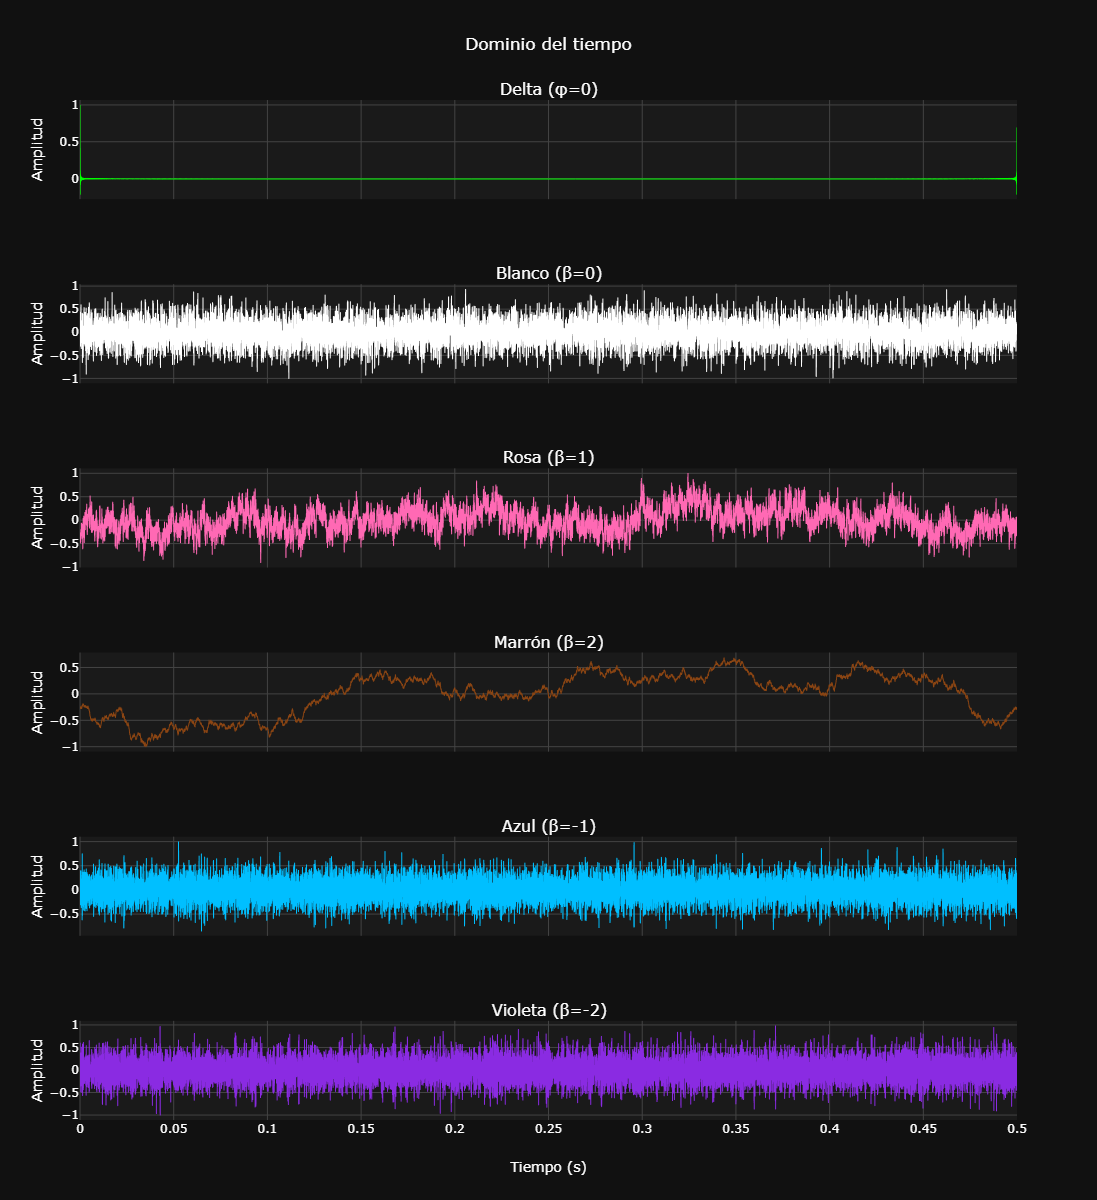

In [6]:
def plot_tiempo(senales, titulos, colores, sec_vis=0.5):
    n_vis = int(sec_vis * SRATE)
    t_vis = np.arange(n_vis) / SRATE
    fig = make_subplots(rows=len(senales), cols=1, shared_xaxes=True,
                        subplot_titles=titulos)
    for i, (sig, color) in enumerate(zip(senales, colores), start=1):
        fig.add_trace(go.Scattergl(
            x=t_vis, y=sig[:n_vis], mode='lines',
            line=dict(color=color, width=1)), row=i, col=1)
        fig.update_yaxes(title_text="Amplitud", row=i, col=1)
    fig.update_layout(title="Dominio del tiempo", height=200 * len(senales), showlegend=False)
    fig.update_xaxes(title_text="Tiempo (s)", row=len(senales), col=1)
    fig.show()

plot_tiempo(
    [h_delta, h_white, h_pink, h_brown, h_blue, h_violet],
    ["Delta (φ=0)", "Blanco (β=0)", "Rosa (β=1)", "Marrón (β=2)", "Azul (β=-1)", "Violeta (β=-2)"],
    [COLOR_DELTA, COLOR_WHITE, COLOR_PINK, COLOR_BROWN, COLOR_BLUE, COLOR_VIOLET]
)

## Autocorrelación

La autocorrelación $R_{xx}(\tau)$ mide cuánto se parece la señal a sí misma desplazada $\tau$ muestras:

- **Blanco**: cae inmediatamente a cero (sin memoria).
- **Rosa**: decae lentamente (memoria de medio alcance).
- **Browniano**: decae muy lentamente (memoria de largo alcance).

Usamos 3000 lags (retrasos) para ver el comportamiento inicial.

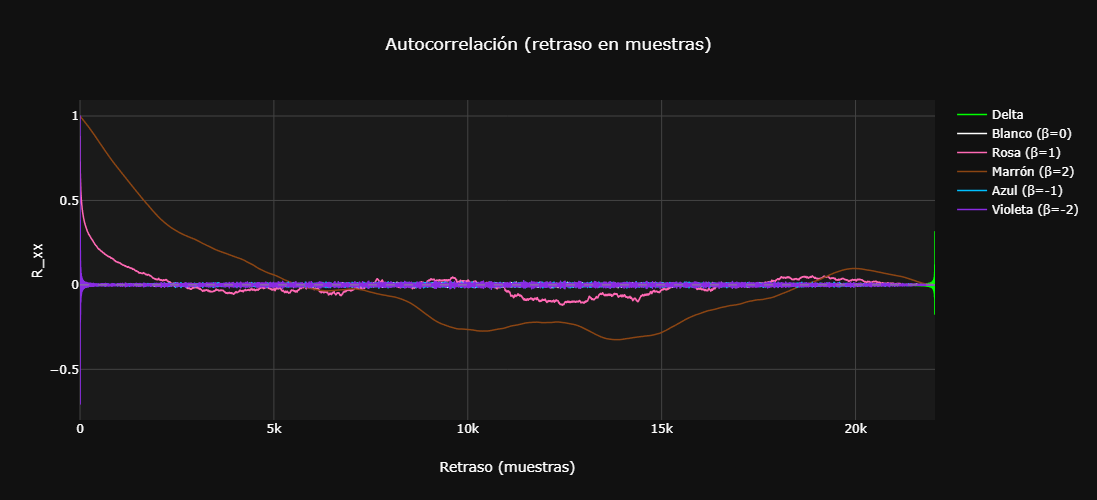

In [11]:
def compute_autocorr(x, max_lag):
    x = x - np.mean(x)
    corr = signal.correlate(x, x, mode='full') / (np.var(x) * len(x))
    centro = len(corr) // 2
    return np.arange(max_lag), corr[centro:centro + max_lag]

def plot_autocorr(senales, titulos, colores, max_lag=22050):
    fig = go.Figure()
    for sig, lbl, color in zip(senales, titulos, colores):
        lags, corr = compute_autocorr(sig, max_lag)
        fig.add_trace(go.Scattergl(x=lags, y=corr, mode='lines',
                                   line=dict(color=color, width=1.5), name=lbl))
    fig.add_hline(y=0, line=dict(color='#888888', width=1, dash='dash'))
    fig.update_layout(title="Autocorrelación (retraso en muestras)",
                      xaxis_title="Retraso (muestras)",
                      yaxis_title="R_xx",
                      height=500)
    fig.show()

plot_autocorr(
    [h_delta, h_white, h_pink, h_brown, h_blue, h_violet],
    ["Delta", "Blanco (β=0)", "Rosa (β=1)", "Marrón (β=2)", "Azul (β=-1)", "Violeta (β=-2)"],
    [COLOR_DELTA, COLOR_WHITE, COLOR_PINK, COLOR_BROWN, COLOR_BLUE, COLOR_VIOLET]
)

## Espectro de potencia (PSD)

La Densidad Espectral de Potencia (PSD) muestra cómo se distribuye la energía por frecuencia.

- **Log-log**: la ley $1/f^\beta$ se vuelve una recta con pendiente $-\beta$.

In [ ]:
def plot_psd_comparativa(senales, titulos, colores, n_fft=N_FFT/2):

    # Creamos la figura con 2 columnas (un panel para cada método)
    fig = make_subplots(
        rows=1, cols=2, 
        subplot_titles=("Método de Welch (falla con la Delta)", 
                        "Periodograma (Correcto para la Delta)")
    )
    
    for sig, lbl, color in zip(senales, titulos, colores):
        # ---------------------------------------------------------
        # PANEL 1: MÉTODO DE WELCH
        # ---------------------------------------------------------
        f_w, Pxx_w = signal.welch(sig, fs=SRATE, nperseg=n_fft, scaling='density')
        mask_w = (f_w > 1) & (f_w < SRATE / 2)
        
        # Calcular pendiente de Welch
        mask_fit_w = (f_w > 10) & (f_w < 5000)
        pend_w, _ = np.polyfit(np.log10(f_w[mask_fit_w]), 
                               np.log10(Pxx_w[mask_fit_w] + 1e-30), 1)
        
        fig.add_trace(go.Scattergl(
            x=f_w[mask_w], y=Pxx_w[mask_w], mode='lines',
            line=dict(color=color, width=1.5), 
            name=f"{lbl} (W) | pend: {pend_w:.2f}"), 
            row=1, col=1)

        # ---------------------------------------------------------
        # PANEL 2: PERIODOGRAMA (FFT Directa)
        # ---------------------------------------------------------
        f_p, Pxx_p = signal.periodogram(sig, fs=SRATE, window='boxcar', scaling='density')
        mask_p = (f_p > 1) & (f_p < F_MAX)
        
        # Calcular pendiente del periodograma
        mask_fit_p = (f_p > 10) & (f_p < 9000)
        pend_p, _ = np.polyfit(np.log10(f_p[mask_fit_p]), 
                               np.log10(Pxx_p[mask_fit_p] + 1e-30), 1)
        
        fig.add_trace(go.Scattergl(
            x=f_p[mask_p], y=Pxx_p[mask_p], mode='lines',
            line=dict(color=color, width=1.5), 
            name=f"{lbl} (P) | pend: {pend_p:.2f}"), 
            row=1, col=2)

    # Configurar los ejes para ambos paneles
    fig.update_xaxes(title_text="Frecuencia (Hz)", type="log", row=1, col=1)
    fig.update_yaxes(title_text="PSD", type="log", row=1, col=1)
    
    fig.update_xaxes(title_text="Frecuencia (Hz)", type="log", row=1, col=2)
    fig.update_yaxes(title_text="PSD", type="log", row=1, col=2)

    fig.update_layout(
        title="Comparativa: Welch vs Periodograma",
        height=550,
        width=1200
    )
    fig.show()

# Llamada
plot_psd_comparativa(
    [h_delta, h_white, h_pink, h_brown, h_blue, h_violet],
    ["Delta", "Blanco (β=0)", "Rosa (β=1)", "Marrón (β=2)", "Azul (β=-1)", "Violeta (β=-2)"],
    [COLOR_DELTA, COLOR_WHITE, COLOR_PINK, COLOR_BROWN, COLOR_BLUE, COLOR_VIOLET]
)

## Espectro de fase

La fase $\angle H(f)$ indica el desfase de cada componente:

- **Delta**: todas las fases son $0$ (coherentes).
- **Blanco**: fases aleatorias uniformes.

In [ ]:
def plot_fase_fft(senales, titulos, colores):
    fig = make_subplots(rows=len(senales), cols=1, shared_xaxes=True,
                        subplot_titles=titulos)
    for i, (sig, color) in enumerate(zip(senales, colores), start=1):
        Y = np.fft.rfft(sig)
        f = np.fft.rfftfreq(len(sig), 1 / SRATE)
        
        # Solo hasta F_MAX para que no se vea ruido numérico
        mask = (f <= F_MAX) 
        
        fig.add_trace(go.Scattergl(x=f[mask], y=np.angle(Y)[mask], mode='markers',
                                   marker=dict(color=color, size=2),
                                   name=titulos[i-1]),
                      row=i, col=1)
        fig.update_yaxes(title_text="Fase (rad)",
                         range=[-np.pi - 0.2, np.pi + 0.2], row=i, col=1)
    fig.update_layout(title="Espectro de fase (FFT)",
                      height=300 * len(senales), showlegend=False)
    fig.update_xaxes(title_text="Frecuencia (Hz)", row=len(senales), col=1)
    fig.show()

plot_fase_fft(
    [h_delta, h_white, h_pink, h_brown, h_blue, h_violet],
    ["Delta", "Blanco", "Rosa", "Marrón", "Azul", "Violeta"],
    [COLOR_DELTA, COLOR_WHITE, COLOR_PINK, COLOR_BROWN, COLOR_BLUE, COLOR_VIOLET],
)

## Coeficientes FFT en el plano complejo

Representamos cada coeficiente $H(f)$ como:

- **Vectores desde el origen** (Re vs Im): se ven las puntas y la dirección.
- **Nube de puntos**: útil para ver la forma (círculo, espiral, dispersión).

Los valores son reales (divididos entre $N$).

In [ ]:
def vectores_desde_origen(mag, fase, max_vectores):
    idx = np.argsort(mag)[-max_vectores:]
    m = mag[idx]
    ph = fase[idx]
    x = m * np.cos(ph)
    y = m * np.sin(ph)
    xv, yv = [], []
    for xi, yi in zip(x, y):
        xv.extend([0, xi, None])
        yv.extend([0, yi, None])
    return np.array(xv), np.array(yv), x, y

def plot_complejo_vectores(senales, titulos, colores, max_vectores=1024):
    n = len(senales)
    fig = make_subplots(rows=1, cols=n, subplot_titles=titulos)
    for i, (sig, color) in enumerate(zip(senales, colores), start=1):
        Y = np.fft.rfft(sig) # Sin normalizar
        xv, yv, x, y_ = vectores_desde_origen(np.abs(Y), np.angle(Y), max_vectores)
        limite = max(np.abs(x).max(), np.abs(y_).max()) * 1.1
        if limite == 0: limite = 1.0

        # Grid: círculos
        for r in np.linspace(limite/5, limite, 5):
            theta = np.linspace(0, 2*np.pi, 100)
            fig.add_trace(go.Scattergl(x=r*np.cos(theta), y=r*np.sin(theta),
                                       mode='lines', line=dict(color='#333333', width=1, dash='dot'),
                                       showlegend=False, hoverinfo='skip'), row=1, col=i)
            fig.add_trace(go.Scattergl(x=[r], y=[0], mode='text', text=[f"{r:.0f}"],
                                       textposition="middle right", showlegend=False), row=1, col=i)

        # Grid: líneas a 45°
        for ang in np.arange(0, 180, 45):
            rad = np.deg2rad(ang)
            fig.add_trace(go.Scattergl(x=[limite*np.cos(rad), -limite*np.cos(rad)],
                                       y=[limite*np.sin(rad), -limite*np.sin(rad)],
                                       mode='lines', line=dict(color='#333333', width=1, dash='dash'),
                                       showlegend=False, hoverinfo='skip'), row=1, col=i)

        # Vectores
        fig.add_trace(go.Scattergl(x=xv, y=yv, mode='lines',
                                   line=dict(color=color, width=0.4),
                                   showlegend=False, hoverinfo='skip'), row=1, col=i)
        fig.add_trace(go.Scattergl(x=x, y=y_, mode='markers',
                                   marker=dict(color=color, size=3),
                                   name=titulos[i-1], showlegend=False), row=1, col=i)

        # Configurar ejes
        eje_x = "xaxis" if i == 1 else f"xaxis{i}"
        eje_y = "yaxis" if i == 1 else f"yaxis{i}"
        ref_y = "y" if i == 1 else f"y{i}"
        fig.layout[eje_x].update(title="Re", scaleanchor=ref_y, scaleratio=1, range=[-limite, limite], showgrid=False, zeroline=False)
        fig.layout[eje_y].update(title="Im", range=[-limite, limite], showgrid=False, zeroline=False)

    fig.update_layout(title="Vectores desde el origen (Grid Polar)", height=650, width=650 * n)
    fig.show()

plot_complejo_vectores(
    [h_delta, h_white, h_pink, h_brown, h_blue, h_violet],
    ["Delta", "Blanco", "Rosa", "Marrón", "Azul", "Violeta"],
    [COLOR_DELTA, COLOR_WHITE, COLOR_PINK, COLOR_BROWN, COLOR_BLUE, COLOR_VIOLET],
    max_vectores=1024
)

## Respuestas

### Delta de Dirac

**1. Que propiedad de la alineacion de fase ($\phi_k = 0$) genera la interferencia instantanea?**

Cuando todas las fases son cero, en $t=0$ todos los cosenos valen 1 y las amplitudes se suman constructivamente:

$$
h(0) = \sum_k A_k \cos(\phi_k) = \sum_k A_k
$$

Para $t \neq 0$ los terminos $\cos(2\pi f_k t)$ oscilan con frecuencias armonicas equiespaciadas ($f_k = k\Delta f$), produciendo interferencia destructiva en casi todo el tiempo y constructiva solo en $t = 0, \pm T, \pm 2T, \dots$ con $T = 1/\Delta f = T_{\text{total}}$. La coherencia de fase perfecta hace que todas las oscilaciones "marchen al unisono" en $t=0$, concentrando la energia en un instante. Es el analogo temporal de una red de difraccion con fases alineadas.

**2. Por que la autocorrelacion de la Delta y del Blanco adoptan una forma equivalente?**

Por el teorema de Wiener-Khinchin, $R_{xx}(\tau) = \mathcal{F}^{-1}\{S_{xx}(f)\}$. Ambas senales tienen PSD plana ($S_{xx}(f) = \text{cte}$), y la transformada inversa de una constante es una delta de Dirac en $\tau = 0$. Por eso ambas presentan un pico agudo en $\tau = 0$ y valores nulos (o fluctuaciones estadisticas en el caso estocastico) para $\tau \neq 0$. La forma de $R_{xx}$ depende solo de la PSD, no de las fases.

**3. Si ambas tienen PSD plana, por que una se manifiesta como pico concentrado y la otra como senal estocastica? Existe diferencia en como se distribuye la energia en frecuencia?**

No hay diferencia en la distribucion de energia espectral: ambas tienen $S_{xx}(f)$ constante. La diferencia esta en la fase. La PSD solo mide $|H(f)|^2$ y es ciega a la fase. La fase determina como se distribuye esa energia en el tiempo: fases alineadas producen suma coherente y pico concentrado; fases aleatorias producen cancelacion parcial en cada instante y una senal impredecible.

**4. Espectro de fases del Delta y del Blanco.**

- Delta: $\angle H(f) = 0$ (o constante) para todas las frecuencias; espectro de fase plano.
- Blanco: $\angle H(f) \sim U[0, 2\pi)$; nube uniforme sin estructura.

**5. Diagrama polar de $H(f)$: Delta (rojo) vs Blanco (azul).**

- Delta: los puntos se agrupan en un solo punto sobre el eje real positivo (magnitud constante, fase cero).
- Blanco: los puntos se distribuyen en un anillo de radio aproximadamente constante con angulos variables, formando una nube circular. Ambas tienen la misma magnitud espectral pero distinta coherencia de fase.

### Memoria en Ruido Rosa (1/f)

**6. Que representa la persistencia de $R_{xx}(\tau)$ en terminos de memoria temporal?**

En el Blanco, $R_{xx}(\tau) \approx 0$ para $\tau > 0$: los valores pasados no influyen en los futuros, el sistema no tiene memoria. En el Rosa y el Browniano $R_{xx}(\tau)$ decae lentamente, indicando correlacion de largo alcance: los valores pasados influyen en los futuros. Esa persistencia es la manifestacion temporal del predominio de bajas frecuencias (componentes lentas que arrastran la senal). Blanco = sin memoria; Rosa = memoria de largo alcance; Browniano = memoria aun mas fuerte (integracion del blanco, camino aleatorio).

**7. Pendiente de la PSD en log-log: coincide con lo esperado?**

La PSD teorica es $S_{xx}(f) \propto 1/f^\beta$, luego $\log S_{xx} = -\beta \log f + \text{cte}$. La pendiente esperada es $-\beta$: $0$ (blanco), $-1$ (rosa), $-2$ (browniano). El ajuste con `np.polyfit(log f, log Pxx, 1)` coincide aproximadamente con $-\beta$ en la region de frecuencias intermedias; en los extremos puede desviarse por efectos de ventana y ruido numerico. Para que la PSD resultante tenga pendiente $-\beta$, las amplitudes deben escalar como $A_k \propto 1/f_k^{\beta/2}$ (ya que la potencia es proporcional a $A_k^2$).

### Resumen

| Senal | $A_k$ | $\phi_k$ | $R_{xx}(\tau)$ | PSD |
|---|---|---|---|---|
| Delta | constantes | 0 (coherentes) | pico en $\tau=0$ | plana |
| Blanco | constantes | aleatorias $U[0,2\pi)$ | pico en $\tau=0$ con fluctuaciones | plana |
| Rosa | $\propto 1/f^{1/2}$ | aleatorias | decaimiento lento | $\propto 1/f$ |
| Browniano | $\propto 1/f$ | aleatorias | decaimiento muy lento | $\propto 1/f^2$ |

Conclusion: el modelo N-Tori es identico en todos los casos; solo cambian $A_k$ y $\phi_k$. La fase controla la coherencia temporal (Delta vs Blanco) y la amplitud controla la distribucion espectral (colores de ruido). PSD y autocorrelacion son duales (Wiener-Khinchin); la fase es la informacion que la PSD no captura.

In [ ]:
#Limpieza
gc.collect()  # Fuerza al recolector de basura a liberar la RAM